In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [3]:
ecom_data = pd.read_csv('./ecommerce_return_classification.csv')

In [4]:
ecom_data.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [5]:
ecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


In [8]:
numerical_features = ecom_data.select_dtypes(include=['int64', 'float64']).columns.to_list()
categorical_features = ecom_data.select_dtypes(include=['object']).columns.to_list()

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['cart_value_usd', 'past_return_rate', 'size_bracketing_flag', 'delivery_days_taken', 'discount_pct_applied', 'newsletter_subscriber', 'return_risk_label']
Categorical Features: ['product_category', 'fit_review_sentiment', 'browser_used', 'checkout_device', 'packaging_color', 'loyalty_card_color']


C:\Users\buzz\AppData\Local\Temp\ipykernel_16108\2452866520.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = ecom_data.select_dtypes(include=['object']).columns.to_list()


In [6]:
ecom_data.describe()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,return_risk_label
count,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.750301,0.284024,0.354160,5.974273,23.879051,0.503508,0.645506
std,121.394772,0.159998,0.478338,3.188330,17.263143,0.500071,0.478440
min,25.010000,0.005000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,135.560000,0.157000,0.000000,3.000000,10.000000,0.000000,0.000000
50%,238.740000,0.265000,0.000000,6.000000,20.000000,1.000000,1.000000
75%,343.920000,0.386000,1.000000,9.000000,40.000000,1.000000,1.000000
max,449.860000,0.884000,1.000000,11.000000,50.000000,1.000000,1.000000


In [9]:
ecom_data.loc[ecom_data.duplicated()]

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label


In [10]:
ecom_data.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [11]:
rows = []

for feature in numerical_features:
    Q1 = ecom_data[feature].quantile(0.25)
    Q3 = ecom_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    below = (ecom_data[feature] < lower_bound).sum()
    above = (ecom_data[feature] > upper_bound).sum()
    total = below + above

    rows.append({
        'feature': feature,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'below_lower': below,
        'above_upper': above,
        'outlier_count': total,
        'outlier_pct': round(total / ecom_data[feature].notna().sum() * 100, 2),
    })

outlier_summary = (
    pd.DataFrame(rows)
    .set_index('feature')
    .sort_values('outlier_count', ascending=False)
)

display(outlier_summary)

,lower_bound,upper_bound,below_lower,above_upper,outlier_count,outlier_pct
feature,,,,,,
past_return_rate,-0.1865,0.7295,0,25,25,0.84
cart_value_usd,-176.9800,656.4600,0,0,0,0.00
size_bracketing_flag,-1.5000,2.5000,0,0,0,0.00
delivery_days_taken,-6.0000,18.0000,0,0,0,0.00
discount_pct_applied,-35.0000,85.0000,0,0,0,0.00
newsletter_subscriber,-1.5000,2.5000,0,0,0,0.00
return_risk_label,-1.5000,2.5000,0,0,0,0.00


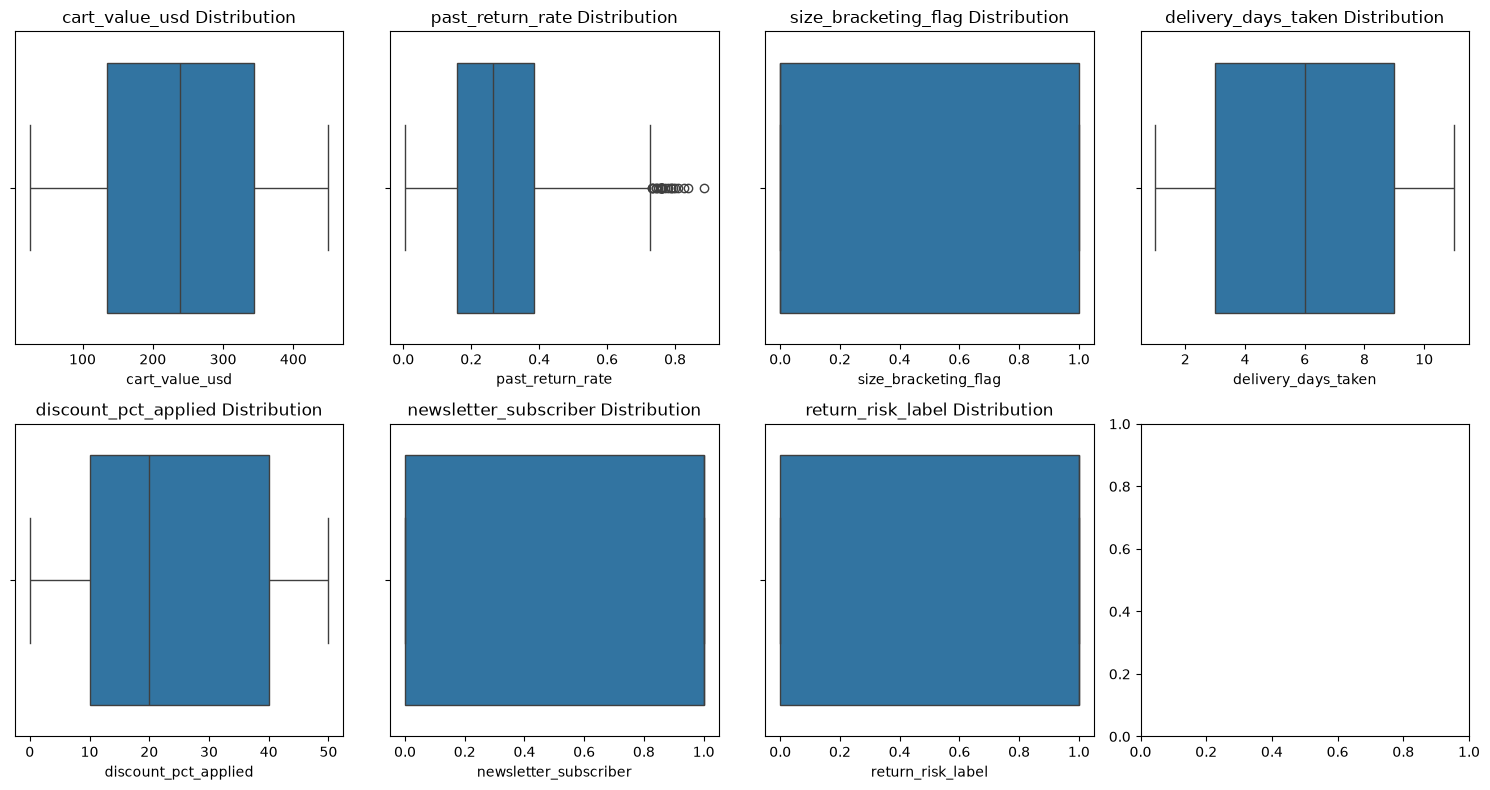

,count
product_category,
Accessories,589
Casual-Tops,1015
Footwear,752
Formal-Eveningwear,637


,count
fit_review_sentiment,
Inconsistent-Sizing,573
Runs-Slightly-Small,922
True-to-Size,1498


,count
browser_used,
Chrome,750
Edge,745
Firefox,752
Safari,746


,count
checkout_device,
Android-App,1036
Desktop-Web,989
iOS-App,968


,count
packaging_color,
Branded-Teal,1001
Kraft-Brown,1010
Minimal-White,982


,count
loyalty_card_color,
Gold,970
Platinum,1023
Silver,1000


In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
  sns.boxplot(data=ecom_data, x=feature, ax=axes[i])
  axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

for feature in categorical_features:
    display(ecom_data.groupby(feature)['return_risk_label'].agg(['count']).round(0))